HOUSE RENT (UNIVARIATE LINEAR REGRESSION)

Data extraction , EDA and Data Processing

In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
whole=pd.read_csv("House_Rent_Dataset.csv")

In [4]:
whole.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Posted On          4746 non-null   object
 1   BHK                4746 non-null   int64 
 2   Rent               4746 non-null   int64 
 3   Size               4746 non-null   int64 
 4   Floor              4746 non-null   object
 5   Area Type          4746 non-null   object
 6   Area Locality      4746 non-null   object
 7   City               4746 non-null   object
 8   Furnishing Status  4746 non-null   object
 9   Tenant Preferred   4746 non-null   object
 10  Bathroom           4746 non-null   int64 
 11  Point of Contact   4746 non-null   object
dtypes: int64(4), object(8)
memory usage: 445.1+ KB


In [5]:
whole["Rent_per_sqft"] = whole["Rent"] / whole["Size"]
whole.groupby("City")["Rent_per_sqft"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
City,,,,
Bangalore,886,21.751740,17.500000,47.911811
Chennai,891,19.785751,16.216216,23.885343
Delhi,605,67.631495,28.571429,90.467248
Hyderabad,868,23.585529,14.545455,70.550080
Kolkata,524,16.491473,13.315603,19.565843
Mumbai,972,81.668894,71.428571,41.495356


<Axes: xlabel='Rent_per_sqft'>

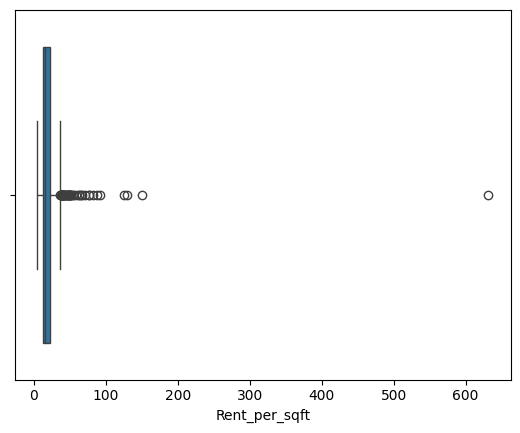

In [6]:
sns.boxplot(x=whole[(whole["City"]=="Chennai") ]["Rent_per_sqft"])


Text(0.5, 1.0, 'Bangalore')

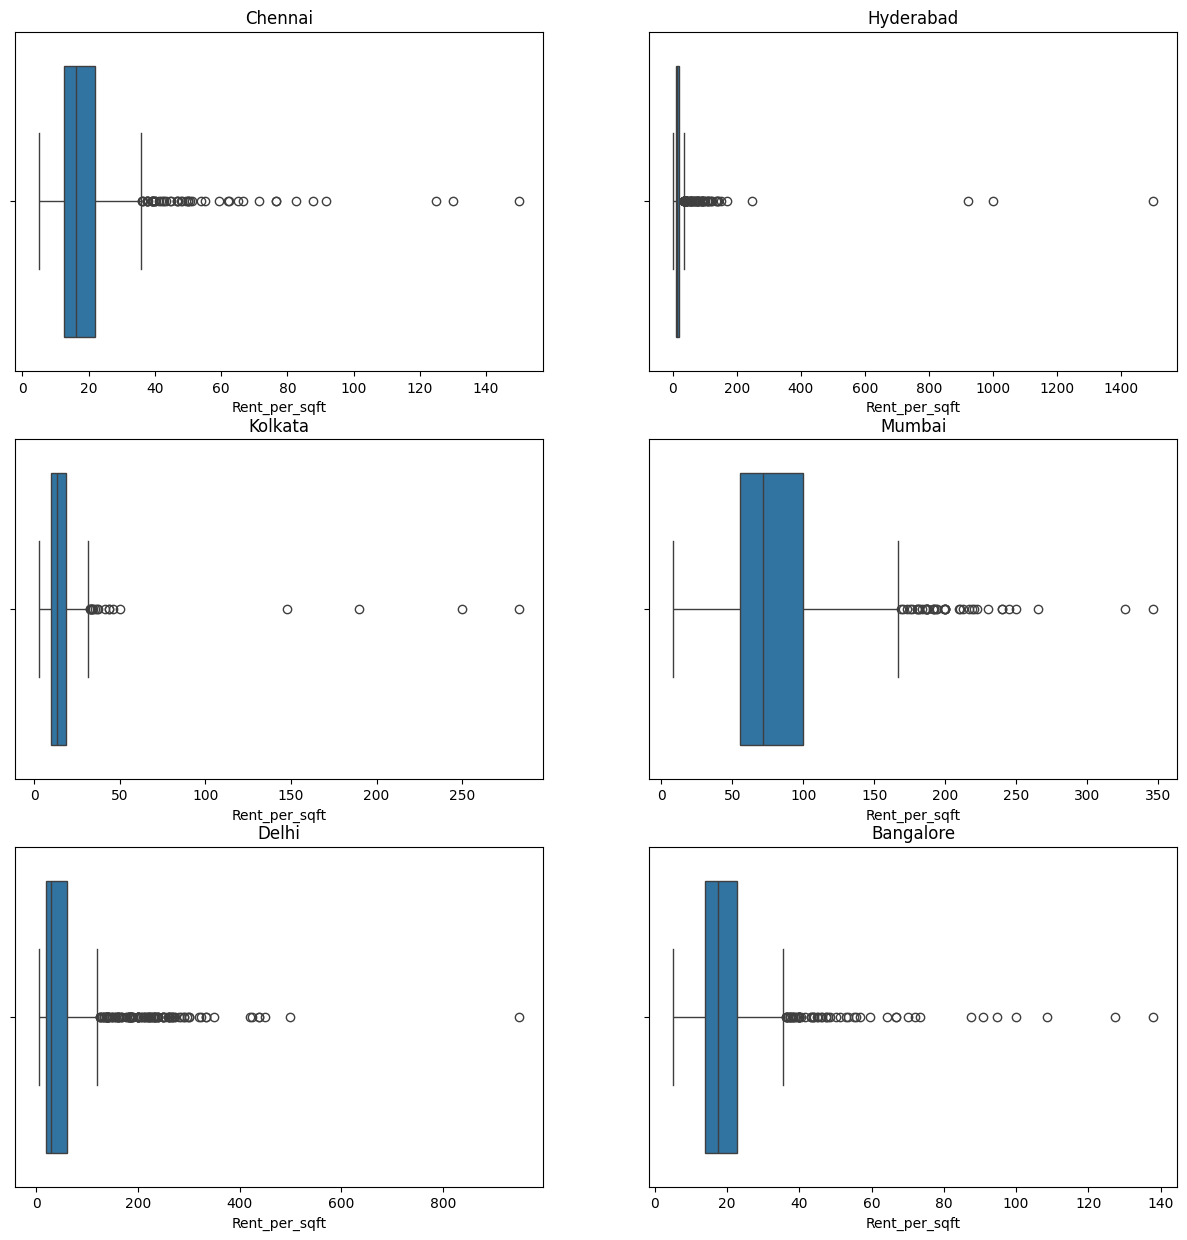

In [7]:
fig ,axes=plt.subplots(3,2,figsize=(15,15))

sns.boxplot(x=whole[(whole["City"]=="Chennai") & (whole["Rent_per_sqft"]<600)]["Rent_per_sqft"] ,ax=axes[0,0])
axes[0,0].set_title("Chennai")
sns.boxplot(x=whole[whole["City"]=="Hyderabad"]["Rent_per_sqft"] ,ax=axes[0,1])
axes[0,1].set_title("Hyderabad")
sns.boxplot(x=whole[whole["City"]=="Kolkata"]["Rent_per_sqft"] ,ax=axes[1,0])
axes[1,0].set_title("Kolkata")
sns.boxplot(x=whole[whole["City"]=="Mumbai"]["Rent_per_sqft"] ,ax=axes[1,1])
axes[1,1].set_title("Mumbai")
sns.boxplot(x=whole[whole["City"]=="Delhi"]["Rent_per_sqft"] ,ax=axes[2,0])
axes[2,0].set_title("Delhi")
sns.boxplot(x=whole[(whole["City"]=="Bangalore") & (whole["Rent_per_sqft"]<1200) ]["Rent_per_sqft"] ,ax=axes[2,1])
axes[2,1].set_title("Bangalore")

In [8]:
whole[(whole["City"]=="Chennai") & (whole["Rent_per_sqft"]>600)]

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Rent_per_sqft
3656,2022-07-06,2,600000,950,1 out of 1,Carpet Area,Vettuvankeni,Chennai,Unfurnished,Bachelors,2,Contact Owner,631.578947


In [9]:
whole.iloc[3656]


Posted On               2022-07-06
BHK                              2
Rent                        600000
Size                           950
Floor                   1 out of 1
Area Type              Carpet Area
Area Locality         Vettuvankeni
City                       Chennai
Furnishing Status      Unfurnished
Tenant Preferred         Bachelors
Bathroom                         2
Point of Contact     Contact Owner
Rent_per_sqft           631.578947
Name: 3656, dtype: object

In [10]:
whole.drop(index=3656,inplace=True) #already

<Axes: xlabel='Rent_per_sqft'>

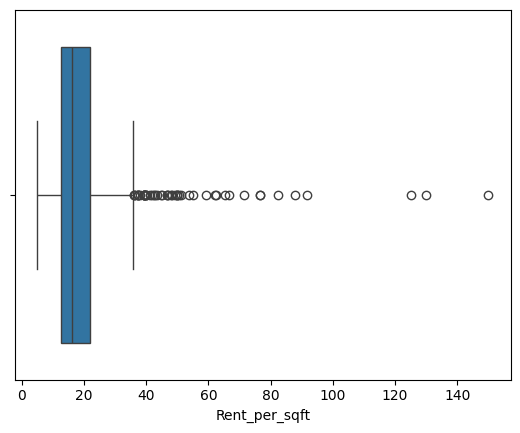

In [11]:
sns.boxplot(x=whole[(whole["City"]=="Chennai") ]["Rent_per_sqft"])

In [12]:
whole_chennai=whole[whole["City"]=="Chennai"]

Feature Extraction

In [13]:
df=whole_chennai[["BHK","Size","Floor","Furnishing Status","Bathroom","Rent"]]
df.describe()
df.info()
df.shape

<class 'pandas.core.frame.DataFrame'>
Index: 890 entries, 2987 to 3877
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   BHK                890 non-null    int64 
 1   Size               890 non-null    int64 
 2   Floor              890 non-null    object
 3   Furnishing Status  890 non-null    object
 4   Bathroom           890 non-null    int64 
 5   Rent               890 non-null    int64 
dtypes: int64(4), object(2)
memory usage: 48.7+ KB


(890, 6)

In [14]:
df = df.sample(frac=1, random_state=42)

In [15]:
df["Furnishing Status"] = df["Furnishing Status"].map({"Unfurnished": 0, "Semi-Furnished": 1, "Furnished": 2})
df.head()

,BHK,Size,Floor,Furnishing Status,Bathroom,Rent
3267,2,650,2 out of 2,2,2,17500
3421,3,1300,19 out of 19,2,3,30000
3026,2,850,Ground out of 2,0,2,12000
3404,1,500,1 out of 4,0,1,18000
3572,2,1000,1 out of 2,0,2,18000


In [16]:
df['Total_Floors']=df["Floor"].str.extract(r"out of\s*(\d+)")[0].astype(float)

In [17]:
df['Floor_no.']=df["Floor"].str.extract(r"^(\d+)")

In [18]:
df["Floor_no."].value_counts()

Floor_no.
1     321
2     164
3      59
4      30
9      13
5      11
7      10
8       7
10      6
15      6
11      6
6       5
12      3
17      2
19      2
20      1
16      1
25      1
13      1
24      1
28      1
14      1
Name: count, dtype: int64

In [19]:
df.loc[df["Floor"].str.startswith("Ground", na=False),"Floor_no."] = 0

df.loc[df["Floor"].str.startswith("Upper Basement", na=False),"Floor_no."] = -1

df.loc[df["Floor"].str.startswith("Lower Basement", na=False),"Floor_no."] = -2

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 890 entries, 3267 to 3089
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   BHK                890 non-null    int64  
 1   Size               890 non-null    int64  
 2   Floor              890 non-null    object 
 3   Furnishing Status  890 non-null    int64  
 4   Bathroom           890 non-null    int64  
 5   Rent               890 non-null    int64  
 6   Total_Floors       890 non-null    float64
 7   Floor_no.          890 non-null    object 
dtypes: float64(1), int64(5), object(2)
memory usage: 62.6+ KB


In [21]:
df["Floor_no."] = df["Floor_no."].astype(float)

In [22]:
df.drop(columns=["Floor"],inplace=True)

In [23]:
df[df["Floor_no."]==-1].value_counts()

BHK  Size  Furnishing Status  Bathroom  Rent  Total_Floors  Floor_no.
1    400   0                  1         8000  2.0           -1.0         1
Name: count, dtype: int64

In [24]:
df=df[['BHK','Size','Furnishing Status','Floor_no.','Total_Floors','Bathroom','Rent']]
df.head()

,BHK,Size,Furnishing Status,Floor_no.,Total_Floors,Bathroom,Rent
3267,2,650,2,2.0,2.0,2,17500
3421,3,1300,2,19.0,19.0,3,30000
3026,2,850,0,0.0,2.0,2,12000
3404,1,500,0,1.0,4.0,1,18000
3572,2,1000,0,1.0,2.0,2,18000


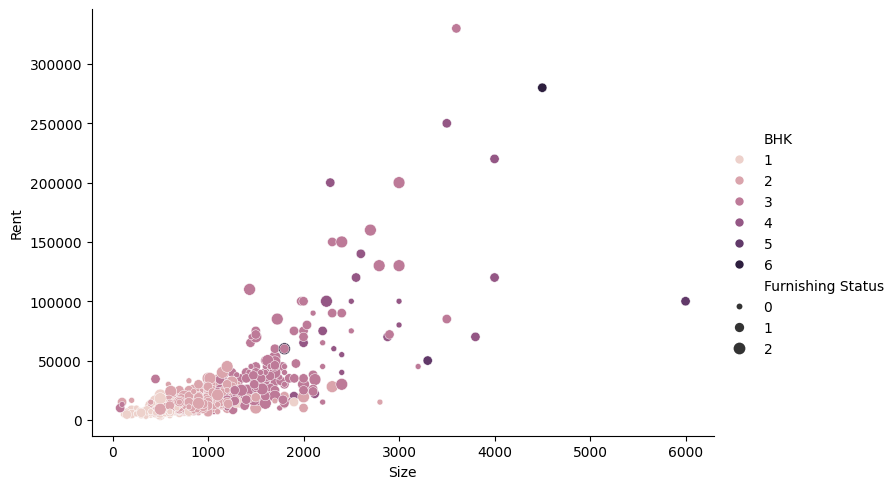

In [28]:
sns.relplot(kind="scatter",data=df,x='Size',y='Rent',hue='BHK',size='Furnishing Status',height=5,aspect=1.5)

<Axes: xlabel='BHK', ylabel='Rent'>

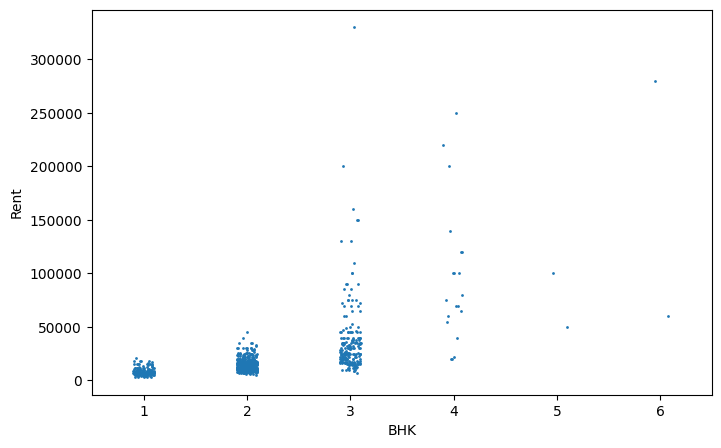

In [29]:
plt.figure(figsize=(8, 5))
sns.stripplot(data=df,x='BHK',y='Rent',size=2)

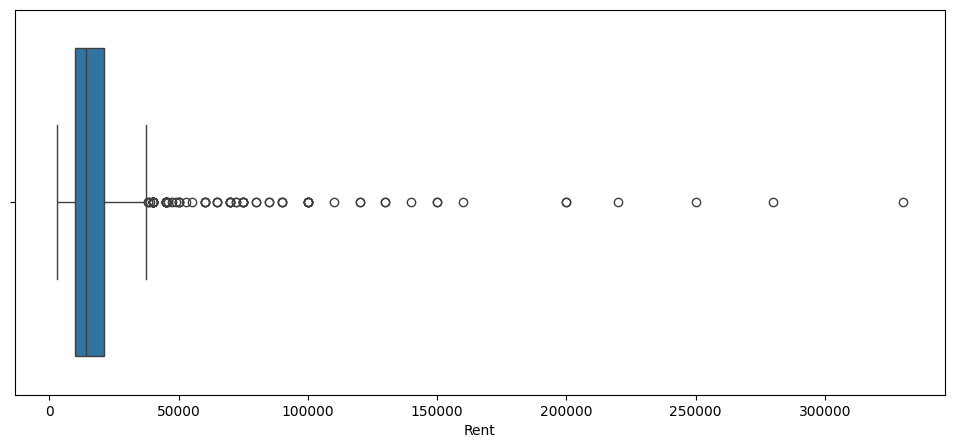

In [30]:
plt.figure(figsize=(12, 5))

sns.boxplot(x=df["Rent"])

plt.show()

<Axes: >

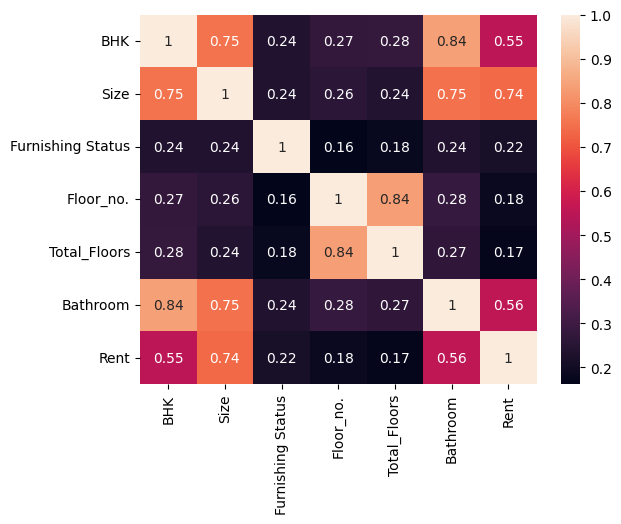

In [31]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

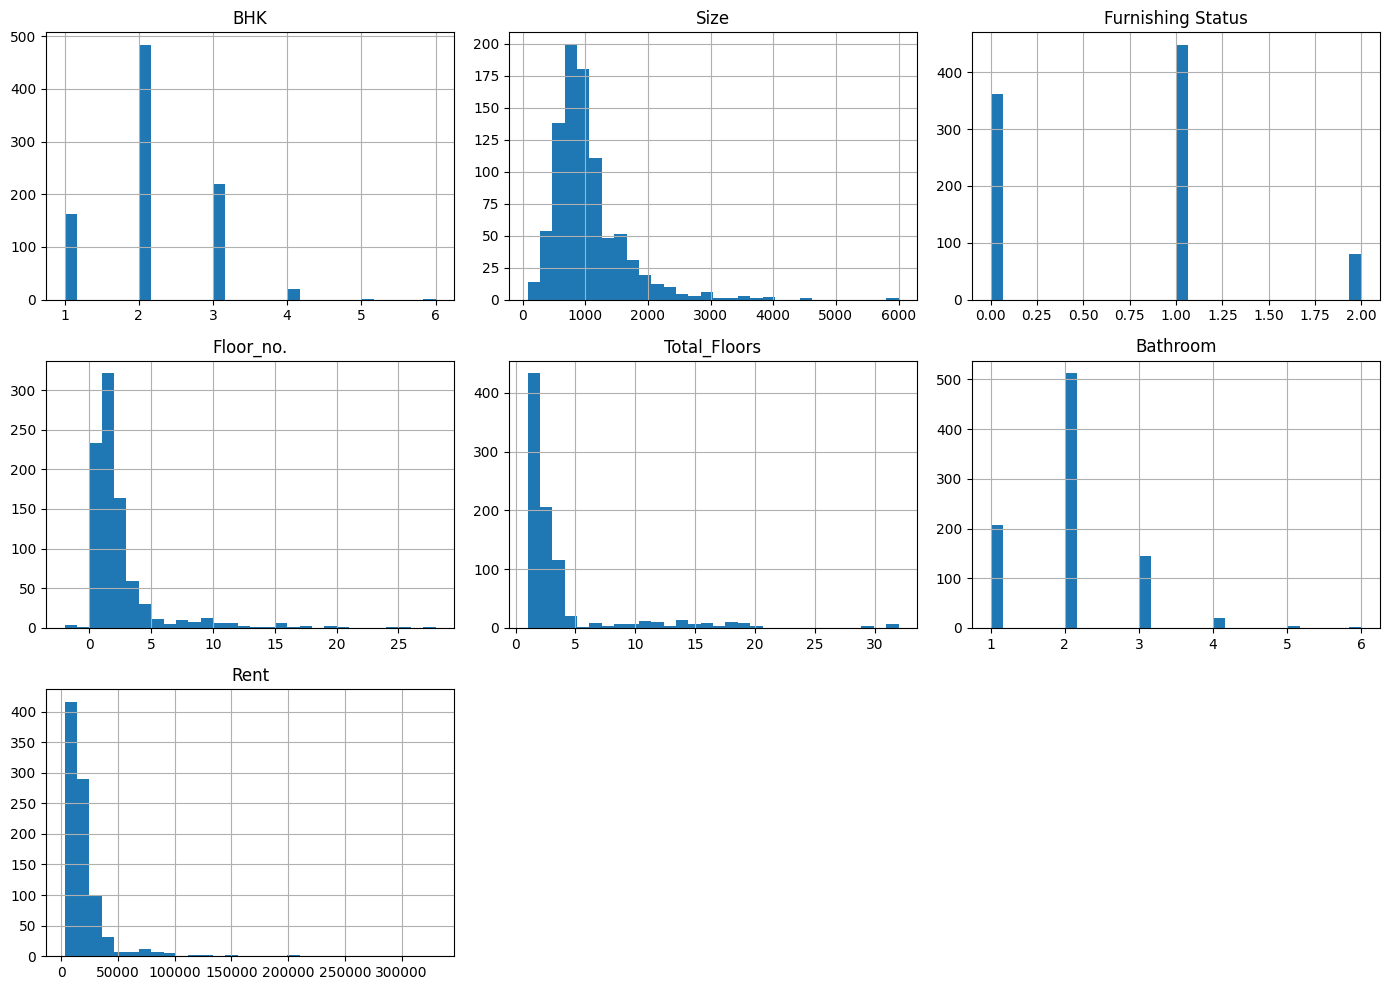

In [32]:
df.hist(figsize=(14, 10), bins=30)

plt.tight_layout()

plt.show()

Univariate Feature

In [33]:
df_uni=df[['Size','Rent']]
df_uni

,Size,Rent
3267,650,17500
3421,1300,30000
3026,850,12000
3404,500,18000
3572,1000,18000
...,...,...
3093,850,24000
3257,900,14000
3848,1500,27000
3422,1484,30000


<Axes: xlabel='Size', ylabel='Rent'>

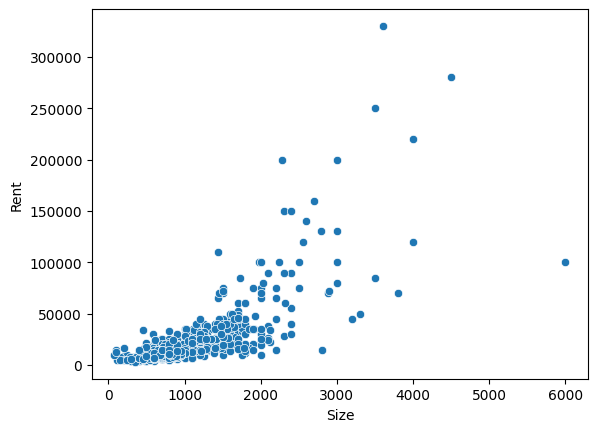

In [34]:
sns.scatterplot(df_uni,x='Size',y='Rent')

In [35]:
df_uni.describe()

,Size,Rent
count,890.000000,890.000000
mean,1031.805618,20964.220225
std,575.752553,26797.888326
min,80.000000,3000.000000
25%,700.000000,10000.000000
50%,900.000000,14000.000000
75%,1200.000000,21000.000000
max,6000.000000,330000.000000


In [36]:
# Find the split point

split = int(0.8 * len(df_uni))

# Split

train_df = df_uni.iloc[:split]

test_df = df_uni.iloc[split:]

In [38]:

X_train, y_train = train_df["Size"], train_df["Rent"]
X_test,  y_test  = test_df["Size"], test_df["Rent"]


# ---------- 3. Z-score scaling (stats from TRAIN only) ----------
mu, sigma = X_train.mean(), X_train.std()
X_train_s = (X_train - mu) / sigma
X_test_s  = (X_test  - mu) / sigma             # reuse train mu/sigma

# ---------- 4. Gradient descent ----------
def gradient_descent(x, y, lr=0.01, epochs=1000):
    w, b = 0.0, 0.0
    m = len(x)
    history = []
    for i in range(epochs):
        y_pred = w * x + b
        error = y_pred - y
        dw = (1 / m) * np.sum(error * x)
        db = (1 / m) * np.sum(error)
        w -= lr * dw
        b -= lr * db
        history.append((1 / (2 * m)) * np.sum(error ** 2))   # cost
        if i % 200 == 0:
            print(f"epoch {i:4d}  cost = {history[-1]:.2f}")
    return w, b, history

w, b, cost_history = gradient_descent(X_train_s, y_train)
print(f"\nLearned (scaled space): w = {w:.2f}, b = {b:.2f}")

# Convert back to original units: y = w_orig * x + b_orig
w_orig = w / sigma
b_orig = b - w * mu / sigma
print(f"In original units:      w = {w_orig:.2f}, b = {b_orig:.2f}")

# ---------- 5. Evaluation metrics ----------
def evaluate(y_true, y_pred):
    mse  = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    mae  = np.mean(np.abs(y_true - y_pred))
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot
    return mse, rmse, mae, r2

train_pred = w * X_train_s + b
test_pred  = w * X_test_s  + b

for name, yt, yp in [("Train", y_train, train_pred), ("Test", y_test, test_pred)]:
    mse, rmse, mae, r2 = evaluate(yt, yp)
    print(f"{name}: MSE={mse:.1f}  RMSE={rmse:.1f}  MAE={mae:.1f}  R2={r2:.4f}")

epoch    0  cost = 548757826.47
epoch  200  cost = 155890934.54
epoch  400  cost = 148821032.17
epoch  600  cost = 148693803.54
epoch  800  cost = 148691513.94

Learned (scaled space): w = 18811.15, b = 21135.30
In original units:      w = 32.68, b = -12780.74
Train: MSE=297382945.5  RMSE=17244.8  MAE=9477.5  R2=0.5430
Test: MSE=456775815.2  RMSE=21372.3  MAE=9156.0  R2=0.5353


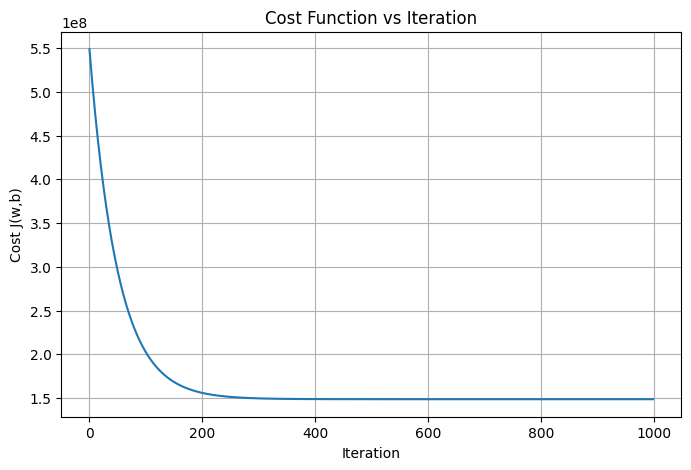

In [39]:
plt.figure(figsize=(8, 5))

plt.plot(cost_history)

plt.xlabel("Iteration")
plt.ylabel("Cost J(w,b)")
plt.title("Cost Function vs Iteration")

plt.grid(True)
plt.show()

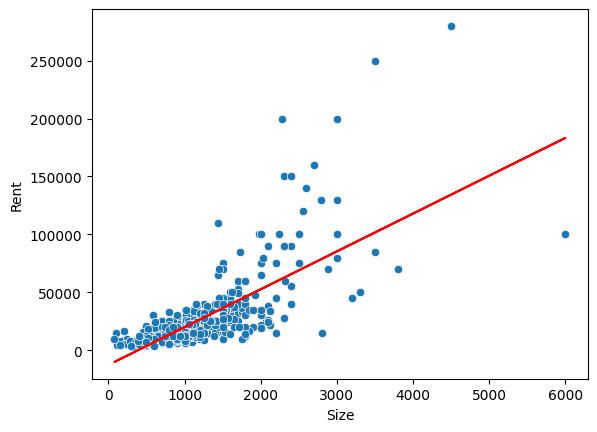

In [40]:
sns.scatterplot(train_df,x='Size',y='Rent')
y_train_predect=w_orig*X_train +b_orig
plt.plot(X_train,y_train_predect,color="red")

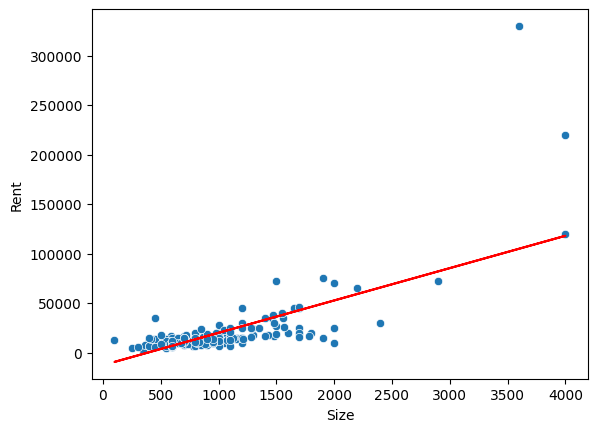

In [41]:
y_test_predect=w_orig*X_test +b_orig
sns.scatterplot(test_df,x='Size',y='Rent')
plt.plot(X_test,y_test_predect,color="red")

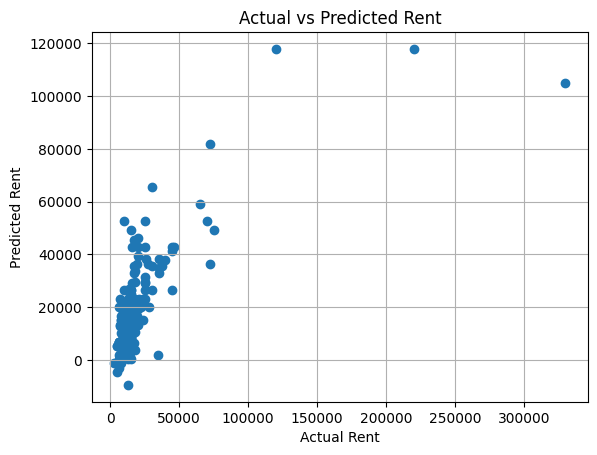

In [42]:


plt.scatter(y_test, y_test_predect)

plt.xlabel("Actual Rent")
plt.ylabel("Predicted Rent")
plt.title("Actual vs Predicted Rent")
plt.grid()
plt.show()

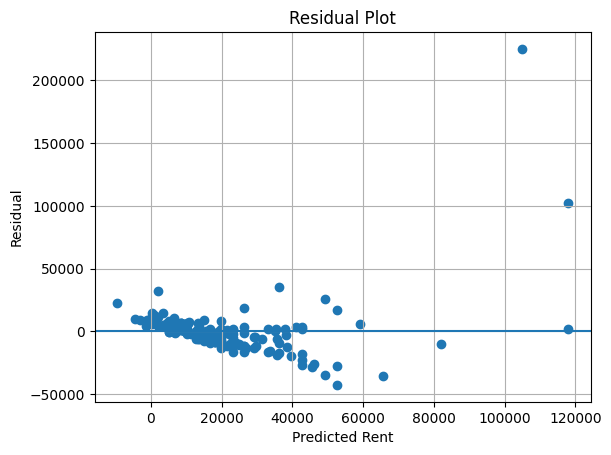

In [44]:
residuals = y_test - y_test_predect
plt.scatter( y_test_predect, residuals)

plt.axhline(0)

plt.xlabel("Predicted Rent")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.grid()
plt.show()